Iteration: 50 | Best Fitness: 146.7665
Iteration: 100 | Best Fitness: 141.1517
Iteration: 150 | Best Fitness: 139.71
Iteration: 200 | Best Fitness: 140.7679
Iteration: 250 | Best Fitness: 139.1134
Iteration: 300 | Best Fitness: 138.5005
Iteration: 350 | Best Fitness: 134.2621
Iteration: 400 | Best Fitness: 130.187
Iteration: 450 | Best Fitness: 129.3585
Iteration: 500 | Best Fitness: 128.7072

FINAL RESULTS
---------------------------
Number of clusters: 3
Number of wolves: 30
Number of iterations: 500
Best Fitness: 128.7072

Cluster Centers:
[[-1.00410294  0.82642504 -1.29781153 -1.26187287]
 [ 1.09595667  0.11569398  0.98999098  1.1082501 ]
 [ 0.0749096  -0.74282654  0.38911117  0.28700414]]

Cluster Distribution:
Cluster 1 : 50 data points
Cluster 2 : 42 data points
Cluster 3 : 58 data points

Adjusted Rand Index: 0.6117


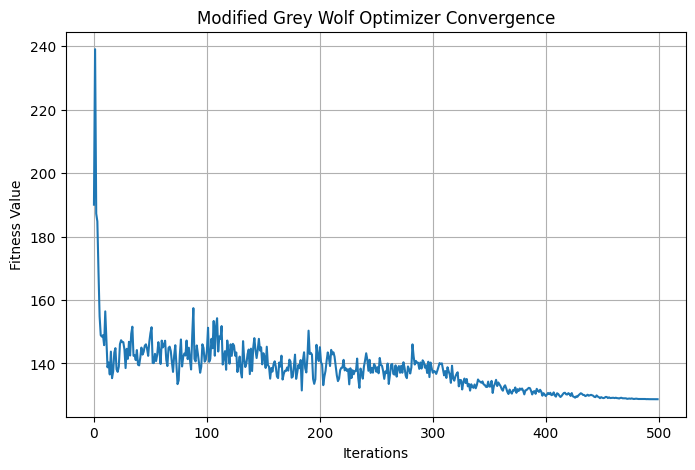

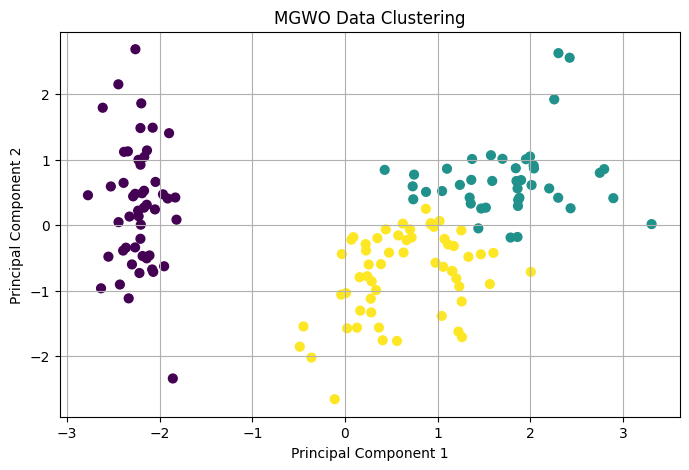

In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score



iris = load_iris()

X = iris.data
actual_labels = iris.target

scaler = StandardScaler()
X = scaler.fit_transform(X)


K = 3


wolves = 30
iterations = 500
k = 2
r = 0.15

np.random.seed(42)


def fitness(position):

    centers = position.reshape(K, X.shape[1])

    distances = np.linalg.norm(
        X[:, np.newaxis, :] - centers[np.newaxis, :, :],
        axis=2
    )

    labels = np.argmin(distances, axis=1)


    total_distance = 0

    for i in range(K):

        cluster_points = X[labels == i]

        if len(cluster_points) == 0:
            return float("inf")

        total_distance += np.sum(
            np.linalg.norm(
                cluster_points - centers[i],
                axis=1
            )
        )

    return total_distance




dimensions = K * X.shape[1]

lower = np.min(X, axis=0)
upper = np.max(X, axis=0)

LB = np.tile(lower, K)
UB = np.tile(upper, K)

population = np.random.uniform(
    LB, UB, (wolves, dimensions)
)


scores = np.array([
    fitness(wolf) for wolf in population
])



def update_leaders():

    order = np.argsort(scores)

    alpha = population[order[0]].copy()
    beta = population[order[1]].copy()
    delta = population[order[2]].copy()

    return alpha, beta, delta


alpha, beta, delta = update_leaders()

best_history = []


z = 0.15


for t in range(iterations):

    a = 2 - 2 * ((t / iterations) ** k)

    for i in range(wolves):

        current = population[i].copy()


        A1 = 2 * a * np.random.rand(dimensions) - a
        C1 = 2 * np.random.rand(dimensions)

        D_alpha = np.abs(C1 * alpha - current)
        X1 = alpha - A1 * D_alpha


        A2 = 2 * a * np.random.rand(dimensions) - a
        C2 = 2 * np.random.rand(dimensions)

        D_beta = np.abs(C2 * beta - current)
        X2 = beta - A2 * D_beta


        A3 = 2 * a * np.random.rand(dimensions) - a
        C3 = 2 * np.random.rand(dimensions)

        D_delta = np.abs(C3 * delta - current)
        X3 = delta - A3 * D_delta


        new_position = (X1 + X2 + X3) / 3


        new_position = np.clip(new_position, LB, UB)

        population[i] = new_position


    scores = np.array([
        fitness(wolf) for wolf in population
    ])

    alpha, beta, delta = update_leaders()




    local_position = (
        alpha + r * (UB - LB) * (z - 0.5)
    )

    local_position = np.clip(
        local_position, LB, UB
    )

    local_fitness = fitness(local_position)
    alpha_fitness = fitness(alpha)


    if local_fitness < alpha_fitness:

        alpha = local_position.copy()


    z = 4 * z * (1 - z)


    best_history.append(fitness(alpha))

    if (t + 1) % 50 == 0:

        print(
            "Iteration:", t + 1,
            "| Best Fitness:", round(fitness(alpha), 4)
        )



best_centers = alpha.reshape(K, X.shape[1])

distances = np.linalg.norm(
    X[:, np.newaxis, :] -
    best_centers[np.newaxis, :, :],
    axis=2
)

final_labels = np.argmin(distances, axis=1)



print("\nFINAL RESULTS")
print("---------------------------")

print("Number of clusters:", K)
print("Number of wolves:", wolves)
print("Number of iterations:", iterations)

print("Best Fitness:", round(fitness(alpha), 4))

print("\nCluster Centers:")
print(best_centers)

print("\nCluster Distribution:")

for i in range(K):
    print(
        "Cluster", i + 1, ":",
        np.sum(final_labels == i), "data points"
    )

print(
    "\nAdjusted Rand Index:",
    round(adjusted_rand_score(actual_labels, final_labels), 4)
)



plt.figure(figsize=(8, 5))

plt.plot(best_history)

plt.xlabel("Iterations")
plt.ylabel("Fitness Value")
plt.title("Modified Grey Wolf Optimizer Convergence")

plt.grid()
plt.show()


pca = PCA(n_components=2)

X_2d = pca.fit_transform(X)

plt.figure(figsize=(8, 5))

plt.scatter(
    X_2d[:, 0],
    X_2d[:, 1],
    c=final_labels,
    cmap="viridis",
    s=40
)

plt.title("MGWO Data Clustering")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.grid()
plt.show()
